# Multi-Sample Processing: Two Xenium Breast Replicates (Python)

Two serial sections of the same tissue, processed one at a time, come out of the cleanup looking different: each section's NMF finds its own set of factors, each section's scoring produces its own rules, and the two cleanups then remove different molecules from the same cell types. This notebook runs the two 10x Genomics Xenium breast cancer replicates through the multi-sample workflow, which treats all samples by one procedure: a shared set of gene programs built from the factorizations of every sample (the consensus factorization), one rule set from the pooled evidence of all samples, and a correction that votes with the same ensemble in every sample. The audit then verifies the cleanup in each sample on its own.

The notebook also explains every diagnostic table the workflow produces, because the diagnostics are how one judges whether the shared treatment suited the samples at hand. The closing section lists what to report from a pilot run on new data. The method and the diagnostics are described in [docs/multisample.md](../../docs/multisample.md); the R version of this notebook is [breast_replicates_multisample.md](breast_replicates_multisample.md), and the single-sample workflow is in the [standalone pancreas tutorial](../xenium_pancreas_membrane_377_full/pancreas_python_standalone.ipynb).

## Inputs

The two replicates are the Xenium FFPE human breast cancer sections published by 10x Genomics (Janesick et al., 2023). Place each bundle in `data/rep1` and `data/rep2`:

```bash
B=https://cf.10xgenomics.com/samples/xenium/1.0.1
curl -O $B/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_outs.zip
curl -O $B/Xenium_FFPE_Human_Breast_Cancer_Rep2/Xenium_FFPE_Human_Breast_Cancer_Rep2_outs.zip
mkdir -p data/rep1 data/rep2
unzip -q Xenium_FFPE_Human_Breast_Cancer_Rep1_outs.zip -d data/rep1
unzip -q Xenium_FFPE_Human_Breast_Cancer_Rep2_outs.zip -d data/rep2
```

The cell-type labels ship with this example under `annotations/`: the supervised labels that 10x published with the dataset for both sections (the `Cell_Barcode_Type_Matrices` supplement), as one `cell_id`, `cell_type` table per replicate. Cells the authors left `Unlabeled` are dropped from the annotation, so they are neither a source nor a target type. The samples must share one gene panel and one annotation scheme; the same labels do not have to be present in every sample.

In [1]:
import functools
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

import celladmix as ca
from celladmix import read_annotation

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def read_labels(path):
    meta = pd.read_csv(path)
    meta = meta[meta["cell_type"] != "Unlabeled"]
    return read_annotation(meta, annotation_col="cell_type")


labels = {
    "rep1": read_labels(Path("annotations/rep1_annotation.csv.gz")),
    "rep2": read_labels(Path("annotations/rep2_annotation.csv.gz")),
}
labels["rep1"].value_counts()

cell_type
Stromal                    41422
Invasive_Tumor             34374
DCIS_1                     12923
DCIS_2                     11683
Macrophages_1              11174
Endothelial                 8931
CD4+_T_Cells                8453
Myoepi_ACTA2+               7078
CD8+_T_Cells                6940
B_Cells                     4987
Prolif_Invasive_Tumor       3775
Myoepi_KRT15+               2860
Macrophages_2               1624
Perivascular-Like            847
Stromal_&_T_Cell_Hybrid      607
T_Cell_&_Tumor_Hybrid        589
IRF7+_DCs                    494
LAMP3+_DCs                   298
Mast_Cells                   167
Name: count, dtype: int64

Each sample is an ordinary cellAdmix dataset with its own output directory, which holds that sample's cache: the prepared molecule store, its fits, and later the shared-profile fits and corrections. The collection groups the datasets under sample names, which prefix the cell ids of every combined output.

In [2]:
datasets = {
    "rep1": ca.CellAdmix("data/rep1", output_dir="out/rep1", annotation=labels["rep1"], num_threads=8),
    "rep2": ca.CellAdmix("data/rep2", output_dir="out/rep2", annotation=labels["rep2"], num_threads=8),
}
collection = ca.CellAdmixCollection(datasets)
collection.samples()

,sample,annotated_cells,cell_types,output_dir
0,rep1,159226,19,out/rep1
1,rep2,115275,19,out/rep2


## Per-sample fits

The consensus is built from the ordinary per-sample fits, so the first step is the same as in the single-sample workflow, once per sample. The rank is derived from the number of annotated cell types, and ten NMF restarts are run per sample; the restarts are the material of the consensus and of the ensemble correction later on. These sections will be cleaned with bridge scoring, which pairs with the `ls_nmf` factorization; on these replicates it removed more admixture at lower own-marker loss than membrane scoring did (see [docs/multisample.md](../../docs/multisample.md)).

In [3]:
collection.fit(nmf_variant="ls_nmf")
collection

Reusing cached run fit_rank23_ls_nmf (parameters match)


Reusing cached run fit_rank23_ls_nmf (parameters match)


CellAdmixCollection(samples=['rep1', 'rep2'], allocation='proportional', fitted=['rep1', 'rep2'])

The stability plot of each fit shows how reproducibly each factor was re-found across the sample's restarts: the y-axis is the correlation of the factor's gene ownership (the share of each gene's molecules the factor claims) with its best match in the other restarts, and the x-axis is the factor's share of all labeled molecules. A stable variant such as `ls_nmf` puts most factors above 0.5. Stability is reported, never used to drop factors; what matters for the next step is that the two samples' restarts agree with themselves to a similar degree, since the consensus keeps the programs that recur across restarts. The figure has one panel per sample, wrapped into rows of four.

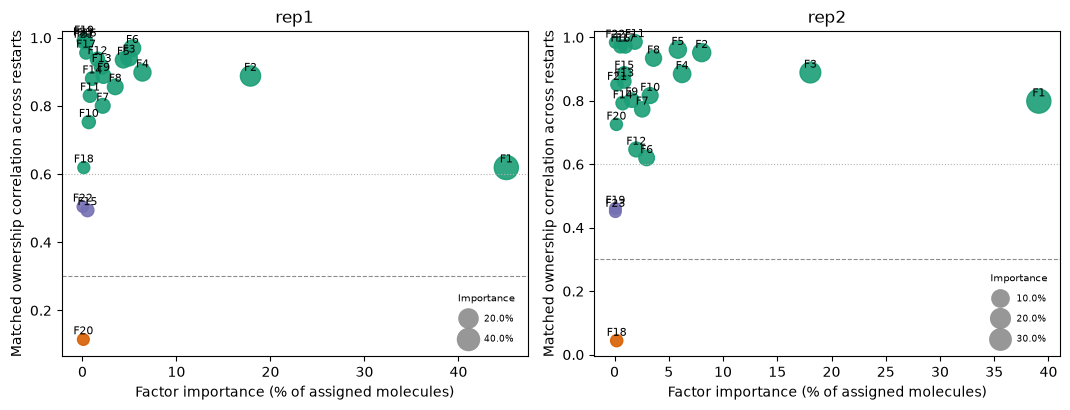

In [4]:
samples = list(collection.fits)
ncols = min(4, len(samples))
nrows = -(-len(samples) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.2 * nrows), squeeze=False)
for ax, sample in zip(axes.ravel(), samples):
    collection.fits[sample].plot_stability(ax=ax)
    ax.set_title(sample)
for ax in axes.ravel()[len(samples):]:
    ax.set_axis_off()
fig.tight_layout()

## Consensus factorization

The consensus pools the factors of every restart of every sample, clusters them into recurring programs, keeps the programs that recur in at least half of some sample's restarts (`min_recurrence=0.5`, the majority rule), takes the per-gene median of each program's members as its shared profile, and then labels every sample's molecules against the shared profiles. The result is one factor index that means the same thing in every sample. The fixed-profile labeling of each sample is cached in that sample's output directory under a run id derived from the profiles, so the step is reused as long as the per-sample fits do not change.

In [5]:
consensus = collection.fit_consensus()
consensus

Reusing cached run consensus_348ab2b2 (parameters match)


Reusing cached run consensus_348ab2b2 (parameters match)


CellAdmixConsensusFit(samples=['rep1', 'rep2'], n_factors=26, single_sample_factors=2, unreproduced_components=37)

The summary reads as follows. **n_factors** is the size of the shared space, to be compared with the per-sample rank: a shared space of about one rank means the two samples found largely the same programs; a much larger one means many programs were specific to one sample; a much smaller one means few programs recurred. **single_sample_factors** counts the shared factors whose cluster contains restarts of a single sample. **unreproduced_components** are pooled factors that no second restart reproduced; they are listed, not used.

### Factors

One row per shared factor:

- `samples` and `coverage`: the number and fraction of samples whose restarts contributed to the cluster.
- `restarts`: how many restarts, over all samples, carried the program (each restart contributes at most one factor to a cluster); `components` counts the contributed factors before that restriction, so a value above `restarts` means some restart split the program in two.
- `max_recurrence`: the largest fraction of any one sample's restarts carrying the program; the majority rule kept the factors with a value of at least 0.5.
- `agreement`: the mean ownership correlation within the cluster, so how alike the contributing factors were.

In [6]:
consensus.factors.round(3)

,consensus_factor,cluster,samples,coverage,restarts,components,max_recurrence,agreement
0,1,2,2,1.0,20,20,1.0,0.896
1,2,11,2,1.0,20,20,1.0,0.745
2,3,7,2,1.0,20,20,1.0,0.839
3,4,13,2,1.0,20,20,1.0,0.938
4,5,6,2,1.0,20,20,1.0,0.846
5,6,10,2,1.0,20,20,1.0,0.949
6,7,12,2,1.0,20,20,1.0,0.809
7,8,18,2,1.0,20,20,1.0,0.946
8,9,21,2,1.0,20,20,1.0,0.918
9,10,23,2,1.0,20,20,1.0,0.832


### Recurrence per sample

The recurrence table gives, per shared factor and sample, the number of that sample's restarts that carried the program and the fraction of its restarts (`recurrence`). A zero marks a program the sample never found on its own; molecules labeled with that factor in the sample are then nearest-profile assignments rather than evidence of the program, which matters for the rule application discussed below.

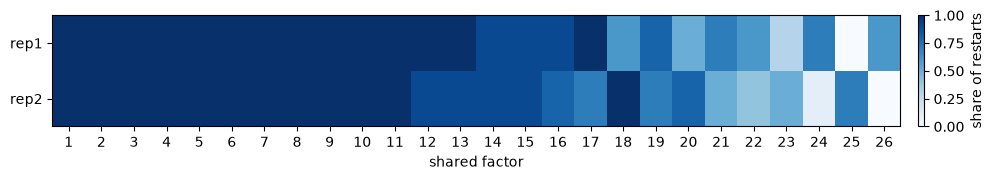

In [7]:
recurrence = consensus.recurrence()
grid = recurrence.pivot(index="sample", columns="consensus_factor", values="recurrence")
fig, ax = plt.subplots(figsize=(10, 1.9))
image = ax.imshow(grid.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_xlabel("shared factor")
fig.colorbar(image, ax=ax, label="share of restarts", fraction=0.025, pad=0.02)
fig.tight_layout()

### Matching of each sample's own factors

The matching table follows each sample's primary factors (the factors of its selected restart, the restart that serves as the sample's own fit) into the shared space: `consensus_factor` is the shared factor whose cluster the primary factor joined (missing and `matched = False` when none), `correlation` is the ownership correlation of the primary factor with that shared profile, `agreement` its mean correlation with the other members of the cluster, and `own_stability` its stability within the sample's own restarts. A primary factor that did not enter the shared space is a program the sample's own restarts mostly did not reproduce either, as its `own_stability` shows; such a program is absent from the shared space and will not be cleaned. The unreproduced components are listed in full with their sample, restart, and factor index; those from a primary restart (`selected`) are the unmatched rows of the matching table.

In [8]:
matching = consensus.matching
matching[(~matching["matched"]) | (matching["correlation"] < 0.8)].round(3)

,sample,sample_factor,consensus_factor,correlation,matched,agreement,own_stability
14,rep1,15,20,0.769,True,0.679,0.494
19,rep1,20,<NA>,NaN,False,0.982,0.115
23,rep2,1,21,0.781,True,0.713,0.799
34,rep2,12,19,0.746,True,0.779,0.647
40,rep2,18,<NA>,NaN,False,0.756,0.044
44,rep2,22,10,0.714,True,0.840,0.984


In [9]:
unreproduced = consensus.unreproduced
print(f"{len(unreproduced)} unreproduced components; from a primary restart:")
unreproduced[unreproduced["selected"]]

37 unreproduced components; from a primary restart:


,sample,restart,factor,group,selected,cluster,agreement,consensus_factor
14,rep1,10,20,10,True,32,0.982447,<NA>
24,rep2,5,18,15,True,24,0.756470,<NA>


### Representation of each sample

The loss table asks whether the shared profiles describe each sample as well as its own factorization does. `own_loss` is the fit objective of the sample's training rows under its own profiles, `consensus_loss` the same objective under the shared profiles, and `loss_gap` their relative difference. The yardstick is `restart_spread`, the relative spread of the objective across the sample's own restarts: a gap within the spread means the consensus fits the sample as well as one of its own restarts would.

In [10]:
consensus.loss.round(4)

,sample,own_loss,consensus_loss,loss_gap,restart_spread
0,rep1,341.5532,338.7575,-0.0082,0.0055
1,rep2,344.1052,342.6620,-0.0042,0.0048


The stability table places each sample's within-sample restart stability next to the agreement of its restarts, aligned to the shared factors, with the consensus profiles. The two numbers being close says the shared profiles are as representative of a sample's restarts as the restarts are of each other.

In [11]:
consensus.stability().round(3)

,sample,within_sample_stability,consensus_agreement,members
0,rep1,0.845,0.907,21
1,rep2,0.811,0.907,21


Factor usage compares how the samples use the shared factors. For every cell type, `sample_usage()` gives the share of the type's molecules labeled with each factor in each sample, and `usage_divergence()` reduces this to one number per type: half the sum of absolute differences between a sample's usage distribution and the pooled one, maximized over samples, so 0 means identical usage and 1 means disjoint factors. For replicates the divergences are small; a type with a large value either differs between the samples in reality (regional sections, different patients) or is labeled with different factors in the two samples, which points to a sample effect in the factorization.

In [12]:
consensus.usage_divergence().head(8).round(3)

,cell_type,divergence,molecules
0,Perivascular-Like,0.039,174886.0
1,Mast_Cells,0.038,51367.0
2,Stromal,0.036,20375495.0
3,IRF7+_DCs,0.031,145267.0
4,Macrophages_2,0.030,632248.0
5,DCIS_2,0.027,6821572.0
6,DCIS_1,0.023,6796373.0
7,Stromal_&_T_Cell_Hybrid,0.023,134214.0


### Per-sample summary and flags

`diagnostics()` gathers the above into one row per sample. The two flags report; nothing is gated on them.

- `representation_flag` is set when `loss_gap` exceeds `restart_spread`: the shared profiles reconstruct the sample's neighborhood compositions worse than one of its own restarts would. This describes reconstruction, not cleanup; a compact shared space can reconstruct the neighborhoods of an unstable factorization poorly and still remove its admixture well, so the per-sample audit below remains the arbiter.
- `shared_factors_flag` is set when fewer than half of the sample's primary factors entered the shared space (`shared_fraction`). It fires when the sample's own restarts disagree among themselves (low `within_sample_stability`): the shared space then holds fewer programs than the sample's own fit, and admixture programs among the lost ones are not cleaned. The first remedy is a more stable NMF variant or more restarts; lowering `min_recurrence` admits the less reproducible programs at the price of more own-marker removal.
- `max_usage_divergence` and `divergent_cell_type` name the cell type whose factor usage differs most between this sample and the pool.

In [13]:
consensus.diagnostics().round(4)

,sample,loss_gap,restart_spread,representation_flag,primary_factors,primary_factors_shared,shared_fraction,shared_factors_flag,within_sample_stability,consensus_agreement,max_usage_divergence,divergent_cell_type
0,rep1,-0.0082,0.0055,False,23,22,0.9565,False,0.8453,0.9073,0.0376,Mast_Cells
1,rep2,-0.0042,0.0048,False,23,22,0.9565,False,0.8110,0.9073,0.0387,Perivascular-Like


## Pooled scoring and rules

Scoring runs per sample: bridge scoring measures, for every target cell type, source cell type, and factor, whether the factor's molecules in target cells sit closer to source cells than the target's other molecules do. The per-sample score tables are then pooled per target, source, and factor: pair counts are summed, mean scores are weighted by pair count, and the one-sided p-values are combined by Stouffer's method with weights proportional to the square root of each sample's pair count. The caps on the number of scored pairs are split between the samples in proportion to their size, so a two-sample collection scores twice the pairs of one sample.

In [14]:
score = consensus.score_bridge()
pooled = score.summary
pooled.sort_values(["p_value", "mean_score"], ascending=[True, False]).head(8)

[INFO 03:51:27 +21.822s] Starting bridge test: molecules=39668814, cells=166534, candidate_mode=cell_center, compute_null=TRUE (0.000s)


[INFO 03:51:28 +22.777s] Prepared bridge data: cell_types=19, factors=26, skipped_unannotated_cells=7308 (0.955s)


[INFO 03:51:29 +24.064s] Discovered bridge candidates: pairs=178805 (1.287s)


[INFO 03:51:46 +40.721s] Scored bridge candidate pairs: score_rows=470955 (16.656s)
[INFO 03:51:46 +40.777s] Selected bridge summary groups: groups=3894, selected_rows=381187 (0.056s)
[INFO 03:51:46 +40.838s] Bridge null setup: groups=3894, selected_rows=381187, unique_pairs=112230, iterations=3, workers=8, fast_crossing=TRUE (0.058s)


[INFO 03:57:57 +411.983s] Bridge null counters: pair_iterations=336690, failed_replacements=0, empty_pairs=0, movement_checks=13530671, avg_checks_per_pair_iter=40.19, movement_reached=147861, movement_unreached=188829, avg_replacement_candidates=13763.7, avg_replacement_pool=1377.9, avg_final_crossing=17.5 (371.146s)
[INFO 03:57:57 +411.984s] Bridge null timing: wall=371.146s, target_cache_sum=59.672s, replacement_sum=900.069s, initialize_sum=22.633s, movement_sum=1132.727s, final_score_sum=30.255s (371.146s)
[INFO 03:57:57 +411.984s] Bridge null target cache: queries=23958806 (371.146s)
[INFO 03:57:57 +411.984s] Bridge null movement kNN: calls=13530671, target_queries=2882782777, table_sum=0.000s, index_sum=0.000s, query_sum=1132.093s (371.146s)
[INFO 03:57:57 +411.984s] Bridge null final kNN: calls=336690, target_queries=71876418, table_sum=0.000s, index_sum=0.000s, query_sum=30.181s (371.146s)
[INFO 03:57:57 +412.032s] Computed bridge null scores (371.255s)
[INFO 03:57:57 +412.042s

[INFO 03:58:23 +18.349s] Starting bridge test: molecules=29089452, cells=118710, candidate_mode=cell_center, compute_null=TRUE (0.000s)


[INFO 03:58:24 +19.060s] Prepared bridge data: cell_types=19, factors=26, skipped_unannotated_cells=3435 (0.712s)


[INFO 03:58:25 +20.033s] Discovered bridge candidates: pairs=124921 (0.972s)


[INFO 03:58:39 +33.489s] Scored bridge candidate pairs: score_rows=336092 (13.456s)
[INFO 03:58:39 +33.537s] Selected bridge summary groups: groups=3469, selected_rows=270875 (0.048s)
[INFO 03:58:39 +33.589s] Bridge null setup: groups=3469, selected_rows=270875, unique_pairs=78473, iterations=3, workers=8, fast_crossing=TRUE (0.050s)


[INFO 04:03:07 +302.316s] Bridge null counters: pair_iterations=235419, failed_replacements=0, empty_pairs=0, movement_checks=9280307, avg_checks_per_pair_iter=39.42, movement_reached=112783, movement_unreached=122636, avg_replacement_candidates=10400.0, avg_replacement_pool=1041.5, avg_final_crossing=19.6 (268.727s)
[INFO 04:03:07 +302.316s] Bridge null timing: wall=268.727s, target_cache_sum=48.571s, replacement_sum=560.857s, initialize_sum=19.078s, movement_sum=946.709s, final_score_sum=25.685s (268.727s)
[INFO 04:03:07 +302.316s] Bridge null target cache: queries=17003328 (268.727s)
[INFO 04:03:07 +302.316s] Bridge null movement kNN: calls=9280307, target_queries=2001636988, table_sum=0.000s, index_sum=0.000s, query_sum=946.206s (268.727s)
[INFO 04:03:07 +302.316s] Bridge null final kNN: calls=235419, target_queries=51009984, table_sum=0.000s, index_sum=0.000s, query_sum=25.608s (268.727s)
[INFO 04:03:07 +302.349s] Computed bridge null scores (268.811s)
[INFO 04:03:07 +302.357s] Su

,target_cell_type,source_cell_type,factor,n_pairs,mean_score,mean_null_score,p_value,neg_log10_p,n_samples
1343,Endothelial,Endothelial,5,800.0,0.094821,0.023649,7.457307e-116,115.127418,2
2916,Myoepi_ACTA2+,Stromal,12,800.0,0.241789,0.062134,2.312869e-114,113.635849,2
3481,Stromal,Endothelial,5,800.0,0.237579,0.051219,2.412418e-109,108.617547,2
322,CD4+_T_Cells,CD8+_T_Cells,3,800.0,0.063411,0.026152,5.034889e-103,102.298010,2
1191,DCIS_2,Myoepi_ACTA2+,21,800.0,0.060808,0.024259,2.110936e-102,101.675525,2
2869,Myoepi_ACTA2+,Myoepi_ACTA2+,16,800.0,0.079706,0.025314,4.892818e-101,100.310441,2
3635,Stromal,Myoepi_ACTA2+,16,800.0,0.201659,0.046023,4.835125e-98,97.315592,2
3134,Perivascular-Like,Endothelial,20,800.0,0.143620,0.058154,1.218824e-97,96.914059,2


In the pooled summary, `n_pairs` is the number of target-source cell pairs the evidence rests on, `mean_score` and `mean_null_score` the proximity statistic and its permutation null, and `n_samples` the number of samples that contributed pairs. `score.sample_summaries()` holds the per-sample tables the pool was built from, one row per sample, target, source, and factor.

The rules select the pooled rows below the p-value threshold and add two kinds of report. `sample_support` is the fraction of samples whose own evidence reaches the threshold for the rule, with those samples named in `samples_significant`; a rule with support 0.5 in a two-sample collection rests on one sample's evidence alone. It is a report, not a gate: in replicates, the rules missing in one sample are the ones that sample's own scoring under-powered, and applying them there is the point of the pooled treatment. The native-factor check (`native_check`) vetoes rules whose factor is a program of the target type itself, judged on pooled evidence: when target cells far from any source still express the factor's genes, removing those molecules would remove native expression, and `keep` is set to `False`.

In [15]:
rules = score.rules()
print(f"{len(rules)} candidate rules; {int(rules['keep'].sum())} kept")
display(pd.crosstab(rules["native_check"], rules["keep"]))
rules.loc[rules["keep"], "sample_support"].value_counts().sort_index()

322 candidate rules; 270 kept


keep,False,True
native_check,,
native_median,18,0
native_outlier,17,0
no_exposed_cells,1,0
no_gradient,16,0
pass,0,270


sample_support
0.5     32
1.0    238
Name: count, dtype: int64

The verdicts of the native-factor check: `native_median` when target cells with no source cell among their neighbors still carry the factor in more than a tenth of their molecules at the median; `native_outlier` when the share of such distant target cells expressing the factor is an outlier among the cell types; `no_gradient` when the factor's share in target cells does not rise with exposure to the source; and `no_exposed_cells` when too few target cells touch the source to judge. A vetoed rule is kept in the table for inspection and not applied.

The pooled evidence is drawn like a single sample's scoring matrix. Rows are cell types, columns the shared factors, and the color is the significance of the pooled evidence that the factor's molecules in cells of that type sit closer to another type's cells than the type's own molecules do. `S` marks the type the factor is called from as its source, `*` marks a removal call (the factor's molecules will be removed from that cell type), and `(*)` a call the native-factor check vetoed because the factor is a program of the type itself.

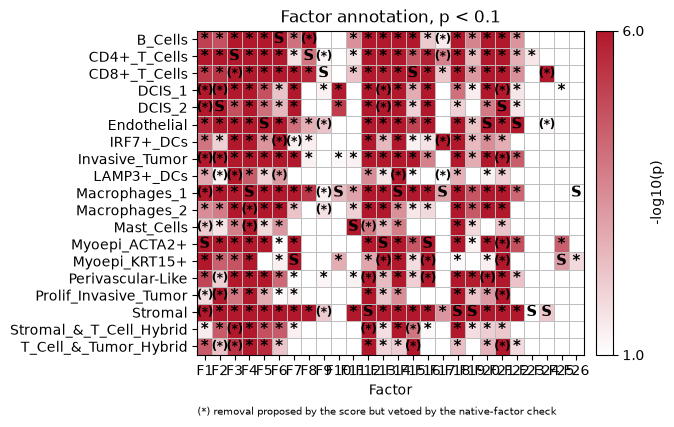

In [16]:
score.plot_heatmap();

## Correction

The correction removes the molecules matched by the rules with a vote across ensemble members, exactly as in the single-sample workflow, with one difference: the ensemble is shared. The restart profiles of all samples, aligned to the shared factors and interleaved, form one member pool; every member labels every sample's molecules, is scored in every sample, and its evidence is pooled like the primary evidence, so one member rule set votes in every sample. A molecule is removed when at least 30% of the members remove it. By default every rule is applied in every sample. The per-sample steps (labeling each sample with every member, scoring every member in every sample, the vote in each sample) run concurrently within a thread budget, here 32 threads.

In [17]:
correction = score.correct(rules=rules, num_threads=32)
correction

Pooled ensemble correction over 10 members shared by 2 samples: molecules removed by >= 3 members (vote >= 0.30) are dropped (rep1: 8,576,659, rep2: 6,699,397).


CellAdmixCollectionCorrection(name='bridge_clean', n_removed={'rep1': 8576659, 'rep2': 6699397})

The rules carried by the correction gain two columns: `support`, the fraction of ensemble members whose own rules contain the rule's source and target pair, and `samples_without_program`, the samples none of whose restarts carry the rule's program (empty for a program every sample found). Under the default the rules on single-sample programs are applied in every sample; the column records where that happened.

In [18]:
applied = correction.rules[correction.rules["keep"]]
display(applied["support"].describe().round(3))
applied["samples_without_program"].value_counts()

count    270.000
mean       0.916
std        0.168
min        0.200
25%        0.900
50%        1.000
75%        1.000
max        1.000
Name: support, dtype: float64

samples_without_program
        267
rep1      2
rep2      1
Name: count, dtype: int64

The correction summary reports, per sample and cell type, the number of cells, how many were modified, molecule counts before and after, the fraction of molecules removed, and the median removal per modified cell. The `all` row is the sample total. A fraction above a few tens of percent for a cell type is not alarming in itself when the type is small and embedded in another (immune cells in tumor, for instance); the audit below says whether what was removed was admixture.

In [19]:
removal = correction.summary()
removal[removal["cell_type"] == "all"].round(3)

,sample,cell_type,n_cells,n_modified_cells,fraction_cells_modified,molecules_before,molecules_after,molecules_removed,fraction_molecules_removed,median_removed_per_modified_cell,median_fraction_removed_per_modified_cell
0,rep1,all,166534,157612,0.946,39668814.0,31092155.0,8576659.0,0.216,28.0,0.167
21,rep2,all,118710,114652,0.966,29089452.0,22390055.0,6699397.0,0.230,36.0,0.204


For replicates the per-type removal fractions should track each other, which is the direct reading of whether the sections were cleaned alike. One point per sample, so the plot reads the same with many samples:

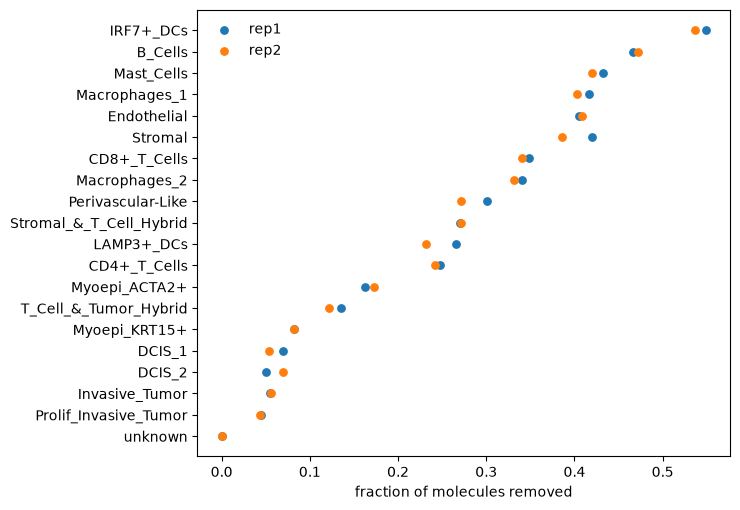

In [20]:
by_type = removal[removal["cell_type"] != "all"]
order = by_type.groupby("cell_type")["fraction_molecules_removed"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for sample, rows in by_type.groupby("sample"):
    rows = rows.set_index("cell_type").reindex(order)
    ax.scatter(rows["fraction_molecules_removed"], range(len(order)), label=sample, s=28)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("fraction of molecules removed")
ax.legend(frameon=False)
fig.tight_layout()

## Audit

The audit estimates, in each sample and before any correction, how much of every target cell type's expression leaked in from each source type, using only the spatial exposure structure: the expression of a source's marker genes in target cells as a function of their exposure to source cells, against a reference of unexposed target cells. `rate` is the estimated share of the target type's molecules that came from the source, `admixed_molecules` the corresponding molecule count, and `detected` whether the pair's exposure gradient is significant. The pooled table sums the molecule counts over samples and records in how many samples the pair was detected (`n_samples_detected`); the per-sample table is available with `by_sample=True`. The messages name the genes the audit dropped from a source's marker panel because their excess in exposed target cells far exceeds what the source's own expression could contribute: such excess is more likely expression induced in the target by the contact than transferred molecules, and it would inflate the leakage estimate.

In [21]:
audit = consensus.audit_admixture()
pairs = audit.pairs(detected_only=True)
pairs.head(10).round(4)

Excluded 34 likely induced genes from marker panels (exposure-linked excess far above the source-profile expectation): TCIM, CXCR4, RUNX1, S100A14, PDK4, CEACAM6, LTB, MMP1


Excluded 37 likely induced genes from marker panels (exposure-linked excess far above the source-profile expectation): RUNX1, TCIM, CXCR4, MMP1, PDK4, LTB, TIMP4, MYBPC1


,source,target,admixed_molecules,rate,detected,n_samples,n_samples_detected
0,Prolif_Invasive_Tumor,Invasive_Tumor,2138776.0,0.1471,True,2,2
1,Macrophages_1,Stromal,1274669.0,0.0626,True,2,2
2,Macrophages_2,Stromal,1081474.0,0.0531,True,2,2
3,CD4+_T_Cells,Stromal,1041389.0,0.0511,True,2,2
4,Invasive_Tumor,Stromal,920142.0,0.0452,True,2,2
5,CD8+_T_Cells,Stromal,762989.0,0.0374,True,2,2
6,Stromal,Endothelial,709650.0,0.2159,True,2,2
7,Endothelial,Stromal,700757.0,0.0344,True,2,2
8,B_Cells,Stromal,655970.0,0.0322,True,2,2
9,Myoepi_ACTA2+,DCIS_1,614022.0,0.0903,True,2,2


### Verification of the cleanup

The audit re-measures the same exposure gradients on the corrected counts of each sample. Its summary has one row per sample:

- `detected_pairs` and `estimated_admixed_molecules`: the size of the problem in the sample before the correction.
- `leakage_removed_overall`: the fraction of the estimated admixed molecules that the correction removed, summed over detected pairs.
- `median_pair_sensitivity`: the median, over detected pairs, of the fraction of each pair's leakage that was removed; it tells whether the cleanup reached the typical pair, not just the largest ones.
- `own_marker_false_removal`: the fraction of the molecules of each cell type's own marker genes, in cells far from any source of them, that the correction removed. These molecules are almost surely genuine, so this is the price of the cleanup; `worst_false_removal` names the type that paid the most.

The method warns when a detected pair kept more than 80% of its leakage and when a type lost more than a quarter of its own markers. In our benchmarks a good cleanup removes 0.6 to 0.7 of the leakage with a median pair sensitivity near 0.9 and own-marker false removal of 1 to 3%.

In [22]:
report = audit.evaluate(correction)
report.summary().round(4)

/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction removed only 0% of the estimated ~173,203 admixed molecules from CD4+_T_Cells into CD8+_T_Cells
  reports = {s: audit.evaluate(corrections[s], **kwargs) for s, audit in self.audits.items()}
/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction removed only 3% of the estimated ~84,515 admixed molecules from DCIS_1 into DCIS_2
  reports = {s: audit.evaluate(corrections[s], **kwargs) for s, audit in self.audits.items()}
/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction removed only 14% of the estimated ~27,746 admixed molecules from DCIS_1 into Myoepi_ACTA2+
  reports = {s: audit.evaluate(corrections[s], **kwargs) for s, audit in self.audits.items()}
/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction remo

/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction removed only 0% of the estimated ~145,545 admixed molecules from CD4+_T_Cells into CD8+_T_Cells
  reports = {s: audit.evaluate(corrections[s], **kwargs) for s, audit in self.audits.items()}
/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction removed only 0% of the estimated ~3,176 admixed molecules from CD4+_T_Cells into Stromal_&_T_Cell_Hybrid
  reports = {s: audit.evaluate(corrections[s], **kwargs) for s, audit in self.audits.items()}
/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: Correction removed only 4% of the estimated ~517,930 admixed molecules from DCIS_1 into DCIS_2
  reports = {s: audit.evaluate(corrections[s], **kwargs) for s, audit in self.audits.items()}
/home/pkharchenko/cellAdmix/wt-dev_multisample/python/src/celladmix/collection.py:963: UserWarning: 

,sample,detected_pairs,estimated_admixed_molecules,leakage_removed_overall,median_pair_sensitivity,own_marker_false_removal
0,rep1,172,12086775,0.5945,0.8718,0.0117
1,rep2,149,10251316,0.6675,0.8738,0.0171


The warnings list the detected pairs of which the correction removed less than a fifth. On these sections they are of one kind: pairs of cell types that share their expression program, such as the two T-cell subsets, the two DCIS states, the two myoepithelial states, the two macrophage populations, invasive tumor and its proliferating state, DCIS and the myoepithelial cells lining the same ducts, or dendritic cells and T cells. Molecules of such a source inside a target cell carry a program the target expresses itself, so no factor separates them from the target's own molecules, and a rule on that factor would remove native expression, which is what the native-factor check vetoes. Their leakage stays, and the audit reports it rather than hiding it. The same pairs are listed for both replicates, which is itself a sign that the two sections were treated alike. A negative sensitivity means the pair's exposure gradient was slightly steeper after the correction than before, which happens for small pairs when removals in the surrounding types shift the reference; it reads as no removal.

The pairs table of the report gives every detected pair's sensitivity per sample; its lower end shows which pairs the rules did not cover.

The admixture maps show each sample's estimates before the correction as a source-by-target matrix next to what the cleanup left: each pair's estimate scaled by the share of its leakage that remains, one row per sample on one color scale. Replicates should show the same pattern of pairs in the before column; a pair present in one row only is a difference between the sections, whether real or technical. The cells that stay dark in the after column are the uncovered pairs the warnings list; the others should fade in both rows alike. With many samples, `samples` selects the rows to draw.

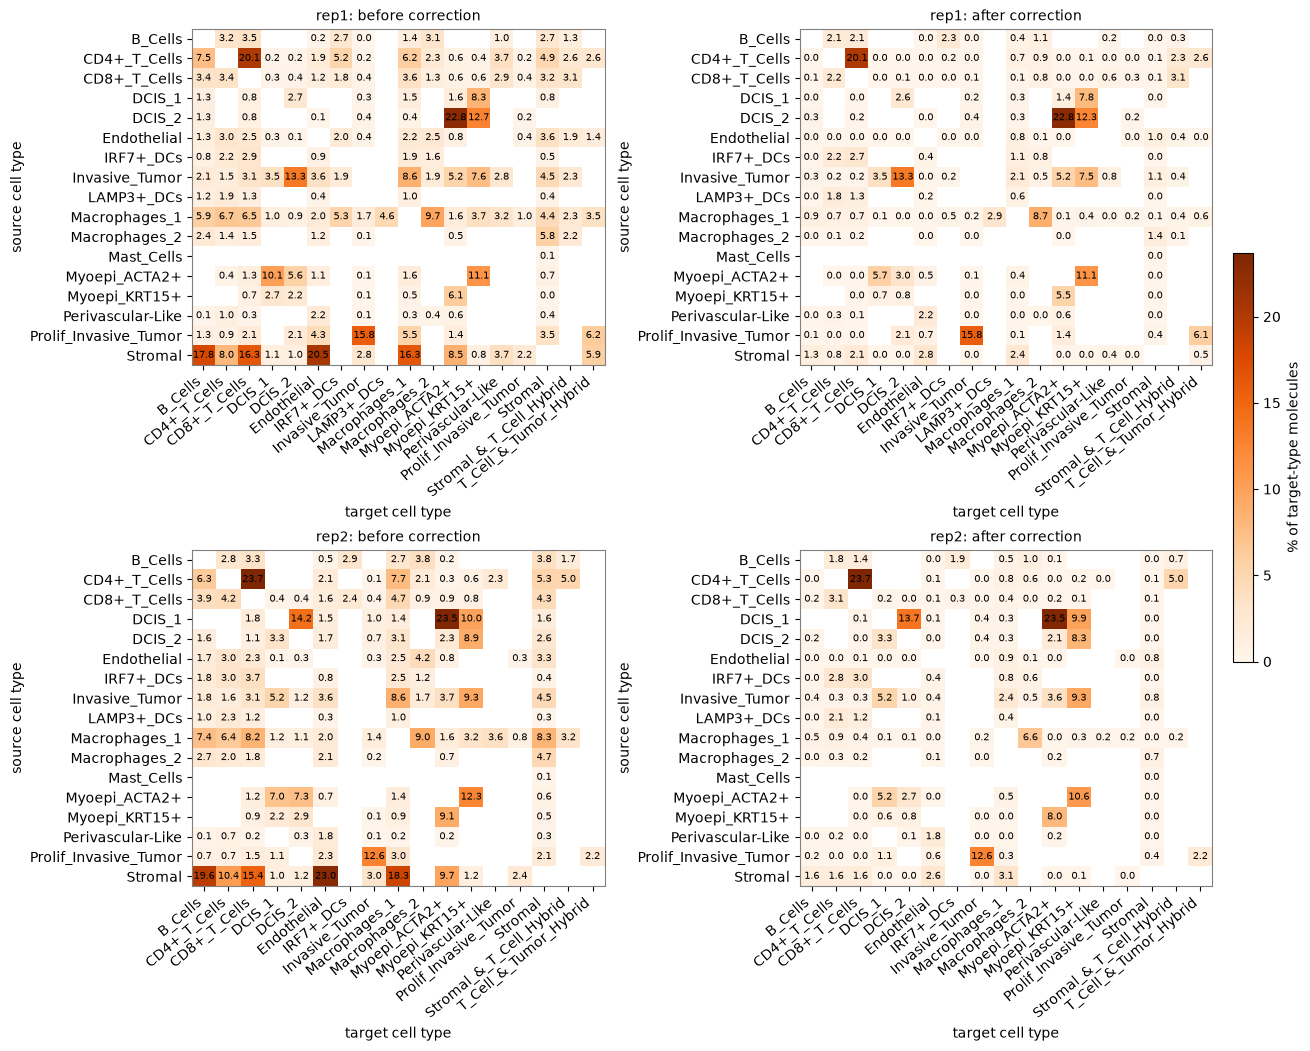

In [23]:
report.plot_map();

In [24]:
report_pairs = report.pairs().sort_values("sensitivity")
report_pairs[["sample", "source", "target", "admixed_molecules", "sensitivity"]].head(8).round(3)

,sample,source,target,admixed_molecules,sensitivity
296,rep2,Perivascular-Like,Endothelial,25169,-0.313
143,rep1,Perivascular-Like,Endothelial,41752,-0.301
25,rep1,CD4+_T_Cells,T_Cell_&_Tumor_Hybrid,2629,-0.054
11,rep1,CD4+_T_Cells,CD8+_T_Cells,173203,-0.050
242,rep2,Invasive_Tumor,DCIS_1,119268,-0.044
209,rep2,DCIS_1,Myoepi_ACTA2+,354017,-0.044
306,rep2,Prolif_Invasive_Tumor,Invasive_Tumor,613924,-0.030
154,rep1,Prolif_Invasive_Tumor,Invasive_Tumor,1524852,-0.028


Two further views complete the verification and read the same with any number of samples. The first is the estimated admixture of each sample's molecules before and after the correction, as bars grouped by sample. The second is each sample's exposure profile: the admixture-marker rate in target cells against the number of source cells among their nearest neighbors, pooled over the detected pairs, which rises with exposure before the correction and should flatten after it; the shaded band between the two curves is the admixture removed at each exposure level.

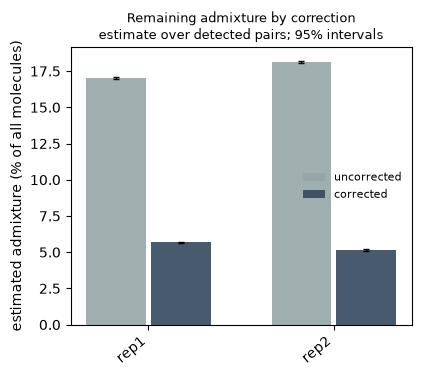

In [25]:
report.plot_remaining();

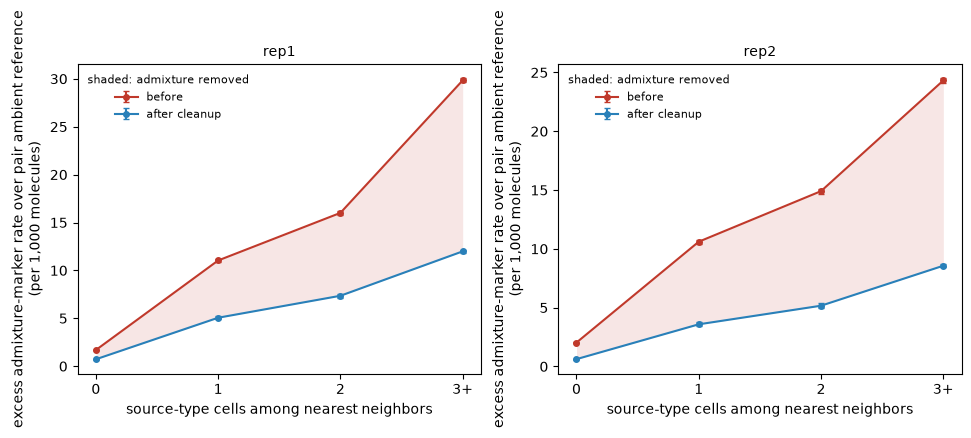

In [26]:
report.plot_exposure();

### Correction diagnostics per sample

`diagnostics(report)` on the correction summarizes, per sample, where the sample's cleanup came from and what the audit made of it:

- `rules_applied`: the number of rules applied in the sample.
- `rules_without_local_evidence` and `removed_without_local_evidence`: the rules the sample's own scoring did not support at the threshold, and the fraction of the sample's removed molecules attributable to them (a removed molecule is attributed to the rule of its cell's type and its primary factor label). For replicates a moderate fraction is the intended uniform treatment; when the samples are not replicates it is a point to examine.
- `rules_on_absent_programs` and `removed_via_absent_programs`: the rules whose program none of the sample's own restarts carries, and the fraction of the removal attributable to them. Such removal cleans the sample of a program it does not have; it is near zero for replicates and becomes substantial when samples differ in composition, which is the case for `apply_rules="where_present"` described below.
- `molecules_removed`, then the audit's leakage removed, median pair sensitivity, and own-marker false removal, with `false_removal_flag` when a sample's false removal exceeds twice the median across samples.

In [27]:
correction.diagnostics(report).round(4)

,sample,rules_applied,rules_without_local_evidence,removed_without_local_evidence,rules_on_absent_programs,removed_via_absent_programs,molecules_removed,leakage_removed_overall,median_pair_sensitivity,own_marker_false_removal,false_removal_flag
0,rep1,270,7,0.0018,2,0.0003,8576659.0,0.5945,0.8718,0.0117,False
1,rep2,270,25,0.0026,1,0.0000,6699397.0,0.6675,0.8738,0.0171,False


## Replicate agreement

The purpose of the shared treatment is that corresponding cell types in the sections stay comparable after the cleanup. One direct measure is, per cell type, the correlation of each sample's pseudobulk expression with the pooled profile of the other samples, averaged over the samples (for two replicates, their mutual correlation), before and after the correction. A cleanup that treats the replicates alike leaves this correlation close to where the uncorrected data had it or raises it; separate per-sample processing lowers it markedly.

,uncorrected,corrected
B_Cells,0.9923,0.9879
CD4+_T_Cells,0.9946,0.9908
CD8+_T_Cells,0.9932,0.9909
DCIS_1,0.9636,0.9799
DCIS_2,0.9674,0.9802
Endothelial,0.9915,0.9914
IRF7+_DCs,0.9741,0.9703
Invasive_Tumor,0.9963,0.9960
LAMP3+_DCs,0.9505,0.9626
Macrophages_1,0.9931,0.9916


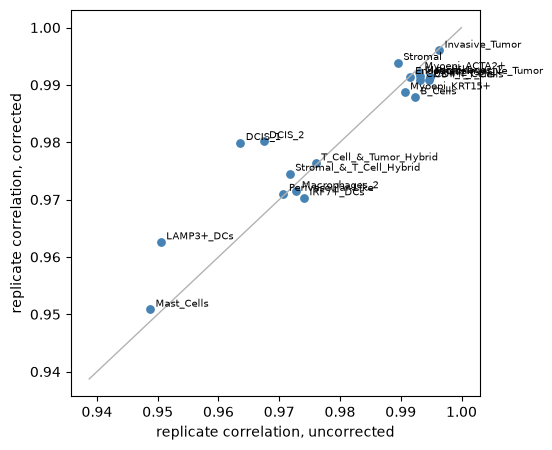

In [28]:
def pseudobulk(counts_tuple, cell_labels):
    counts, genes, cells = counts_tuple
    cell_labels = cell_labels.copy()
    cell_labels.index = cell_labels.index.astype(str)
    types = cell_labels.reindex(pd.Index(cells).astype(str))
    keep = np.flatnonzero(types.notna().to_numpy())
    codes = pd.Categorical(types.iloc[keep])
    indicator = sp.csr_matrix((np.ones(len(keep)), (np.arange(len(keep)), codes.codes)),
                              shape=(len(keep), len(codes.categories)))
    return pd.DataFrame((counts[:, keep] @ indicator).toarray(), index=genes, columns=codes.categories)


def replicate_agreement(get_counts):
    pb = {s: pseudobulk(get_counts(s), labels[s]) for s in labels}
    genes = functools.reduce(lambda a, b: a.intersection(b), [p.index for p in pb.values()])
    types = functools.reduce(lambda a, b: a.intersection(b), [p.columns for p in pb.values()])

    def agreement(t):  # each sample against the pooled profile of the other samples, averaged
        values = []
        for s in pb:
            others = sum(pb[o].loc[genes, t] for o in pb if o != s)
            values.append(np.corrcoef(np.log1p(pb[s].loc[genes, t]), np.log1p(others))[0, 1])
        return float(np.mean(values))

    return pd.Series({t: agreement(t) for t in types})


agreement = pd.DataFrame({
    "uncorrected": replicate_agreement(lambda s: consensus.counts(sample=s)),
    "corrected": replicate_agreement(lambda s: correction.counts(sample=s)),
})
display(agreement.round(4))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
lo = min(agreement.min()) - 0.01
ax.plot([lo, 1], [lo, 1], color="0.7", lw=1)
ax.scatter(agreement["uncorrected"], agreement["corrected"], color="steelblue", s=28)
for cell_type, row in agreement.iterrows():
    ax.annotate(cell_type, (row["uncorrected"], row["corrected"]), fontsize=7,
                xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("replicate correlation, uncorrected")
ax.set_ylabel("replicate correlation, corrected")
fig.tight_layout()

## Use the corrected counts

The combined matrix carries cell ids prefixed with the sample name, the convention of Seurat's `merge()`; the per-sample accessor returns the sample's original ids. Each accessor returns the sparse genes-by-cells matrix with its gene and cell indexes.

In [29]:
counts, genes, cells = correction.counts()
print(counts.shape, cells[:3].tolist())
rep1_counts, rep1_genes, rep1_cells = correction.counts(sample="rep1")
print(rep1_counts.shape, rep1_cells[:3].tolist())

(321, 285244) ['rep1_565', 'rep1_562', 'rep1_271']


(321, 166534) ['565', '562', '271']


## Samples that are not replicates

When the samples differ in composition (regional sections, different patients), a program found by one sample's restarts may be absent from another's. Under the default `apply_rules="everywhere"` the rule is still applied there, where it removes the molecules labeled with the nearest shared profile. `score.correct(rules=rules, apply_rules="where_present")` applies each rule only in the samples whose own restarts carry its program. On replicates this costs sensitivity and replicate agreement, since corresponding regions are no longer cleaned alike; the per-sample `removed_via_absent_programs` says how much of a sample's removal the choice would change. See [docs/multisample.md](../../docs/multisample.md) for the measured trade-off.

## What to report from a pilot run

The tables and figures above are the material for judging a run on new data. A report back should include:

1. `collection.samples()`: the samples, their annotated cell counts and number of cell types, and the thread settings and run time.
2. The printed consensus summary and `consensus.diagnostics()`: the size of the shared space against the rank, the single-sample factors, the loss gap against the restart spread, the shared fraction of primary factors, both flags, and the most divergent cell type with its divergence.
3. `consensus.factors` with the recurrence heatmap, and the stability plots of the per-sample fits.
4. The rule counts: candidates, kept, the native-check table, the `sample_support` distribution of the kept rules, and the pooled scoring matrix.
5. `correction.summary()` for the `all` rows and the per-type removal plot, which shows whether the samples were cleaned alike.
6. `report.summary()` and `correction.diagnostics(report)`, with any warnings printed by `evaluate()`, the admixture maps before and after the correction, the remaining-admixture bars, and the exposure profiles.
7. The replicate-agreement table when the samples are replicates.

Points to flag explicitly: either flag set in `consensus.diagnostics()`; own-marker false removal above about 5% or a `false_removal_flag`; median pair sensitivity below about 0.7; samples whose removal fraction for the same cell type differs by more than a few percentage points; many shared factors from one sample only, or a large `removed_via_absent_programs`, which say the samples differ in composition and raise the question of `apply_rules="where_present"`.